# Query value along a ray

We ask how a two-qubit data-reuploading circuit responds when the query *value* changes while the query encoding stays fixed. The data vector $\boldsymbol x$ and the query vector $\boldsymbol f$ are encoded in alternating layers, one component per qubit, and the query is swept along the ray $\boldsymbol f(t) = t\,\boldsymbol d$ with direction $\boldsymbol d = (1, 1)$ and $t \in [0, 2\pi]$. An absorbable (local) and a nonabsorbable (nonlocal) query-generator pair with the same spectrum, together with two parameter priors, Haar and a narrow Gaussian, give one series for each case of the trichotomy: (I) inert, (II) reweighting, (III) class change.

For each $t$ we compute the naive shape change $\Delta(t)$, the class witness $S(t)$ and the jackknife-corrected spectral-prior distance $D_\Sigma(t)$. These curves feed panels (d)–(f) of the combined figure drawn in `fig_01_02_combined.ipynb`; the plot at the end of this notebook is only a diagnostic.

**Outputs.** `results/fig_01_02/query_inductive_bias_product_results.npz` — the three curves per series and the Haar noise ceiling; no figure files are written.

**Runtime.** With the cached results in `results/fig_01_02/` the notebook runs in under a minute. Recomputing from scratch takes about 3 minutes on a laptop CPU (5000 parameter samples per series): delete the cached file. The structural validations and the fixed-parameter shape change are recomputed on every run, and the latter is compared with the cache.

## Setup

We import the numerical libraries and create the results directory, which this notebook shares with `fig_01_vary_encoding.ipynb`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = Path("../results/fig_01_02")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Configuration

The defaults reproduce the paper. Every setting can be overridden through an environment variable: `N_ENSEMBLE`, `N_SCHMIDT`, `N_QUERY_POINTS`, `GRID_SIZE`, `RAY_GRID_SIZE`, `N_JACKKNIFE_BLOCKS`, `NARROW_SIGMA`, `QUERY_DIRECTION`, `QUERY_GRID_SIZE`, `N_SPECTRUM_CHECK` and `TRAINABLE_BLOCKS`. For example, `N_ENSEMBLE=100` is a quick check; the prior-separation check then only warns. `TRAINABLE_BLOCKS=cnot` adds a fixed CNOT after every product block; it is a robustness variant and is not used in the paper.

In [2]:
NUMBER_OF_LAYERS = 2
QUERY_WEIGHTS = np.array([1, 2], dtype=int)

# The query f = (f_0, f_1) is swept along the ray f(t) = t * direction,
# so the abscissa is the ray parameter t.
QUERY_DIRECTION = np.asarray(
    [
        float(component)
        for component in os.environ.get(
            "QUERY_DIRECTION", "1,1"
        ).split(",")
    ],
    dtype=float,
)
if QUERY_DIRECTION.size != 2:
    raise ValueError("QUERY_DIRECTION must have two components.")

# Four product blocks W_l, V_l (l = 1, 2), each with 2 x 3 Euler angles,
# giving 4 x 6 = 24 parameters.
NUMBER_OF_TRAINABLE_BLOCKS = 2 * NUMBER_OF_LAYERS
PARAMETERS_PER_BLOCK = 6
NUMBER_OF_PARAMETERS = (
    NUMBER_OF_TRAINABLE_BLOCKS * PARAMETERS_PER_BLOCK
)

GRID_SIZE = int(os.environ.get("GRID_SIZE", "8"))
# 0 means: size the ray grid from the accessible ray modes.
RAY_GRID_SIZE = int(os.environ.get("RAY_GRID_SIZE", "0"))
NUMBER_OF_ENSEMBLE_SAMPLES = int(
    os.environ.get("N_ENSEMBLE", "5000")
)
NUMBER_OF_SCHMIDT_SAMPLES = int(
    os.environ.get("N_SCHMIDT", "1000")
)
NUMBER_OF_QUERY_POINTS = int(
    os.environ.get("N_QUERY_POINTS", "181")
)
# Grid for the joint (f_0, f_1) spectrum check; it must exceed twice the
# largest query frequency to detect out-of-support content.
QUERY_GRID_SIZE = int(os.environ.get("QUERY_GRID_SIZE", "24"))
NUMBER_OF_SPECTRUM_CHECK_SAMPLES = int(
    os.environ.get("N_SPECTRUM_CHECK", "4")
)
SPECTRUM_CHECK_SEED = 99
# A query-Fourier mode counts as occupied above this magnitude. Populated
# modes sit far above it and vanishing ones near machine precision, so
# the classification is insensitive to the exact threshold.
SPECTRUM_OCCUPATION_TOLERANCE = 1e-10
NUMBER_OF_JACKKNIFE_BLOCKS = int(
    os.environ.get("N_JACKKNIFE_BLOCKS", "10")
)

# Standard deviation of the non-Haar Euler-angle prior, in radians.
NARROW_SIGMA = float(os.environ.get("NARROW_SIGMA", "0.35"))

TRAINABLE_BLOCKS = os.environ.get(
    "TRAINABLE_BLOCKS", "product"
).lower()
if TRAINABLE_BLOCKS not in {"product", "cnot"}:
    raise ValueError(
        "TRAINABLE_BLOCKS must be either 'product' or 'cnot'."
    )
RANK_TOLERANCE = 1e-9

FIXED_PARAMETER_SEED = 5
NARROW_FIXED_PARAMETER_SEED = 7
ENSEMBLE_SEED = 1234
NARROW_ENSEMBLE_SEED = 4321

Each series pairs a query generator pair with a parameter prior; the model section below explains which case each one realizes. Any setting that enters the numbers and differs from its default sends the results to a separate `*_custom_results.npz` file, so the cached paper results are never overwritten.

In [3]:
# Each series is a pair (query encoding, parameter distribution).
SERIES = ("nonlocal", "local", "local_narrow")
QUERY_TYPE_OF_SERIES = {
    "nonlocal": "nonlocal",
    "local": "local",
    "local_narrow": "local",
}
DISTRIBUTION_OF_SERIES = {
    "nonlocal": "haar",
    "local": "haar",
    "local_narrow": "narrow",
}
ABSORBABLE_SERIES = ("local", "local_narrow")
QUERY_TYPES = ("local", "nonlocal")

# The cache is shared with the paper run only if every setting that enters
# the numbers is at its default; anything else gets its own file.
PAPER_SETTINGS = (
    GRID_SIZE == 8
    and RAY_GRID_SIZE == 0
    and NUMBER_OF_ENSEMBLE_SAMPLES == 5000
    and NUMBER_OF_SCHMIDT_SAMPLES == 1000
    and NUMBER_OF_QUERY_POINTS == 181
    and NUMBER_OF_JACKKNIFE_BLOCKS == 10
    and NARROW_SIGMA == 0.35
    and np.array_equal(QUERY_DIRECTION, [1.0, 1.0])
)
RESULTS_PATH = RESULTS_DIR / (
    f"query_inductive_bias_{TRAINABLE_BLOCKS}"
    + ("" if PAPER_SETTINGS else "_custom")
    + "_results.npz"
)
print(f"Results file: {RESULTS_PATH}")

Results file: ../results/fig_01_02/query_inductive_bias_product_results.npz


## Model

The circuit is
$$
U(\boldsymbol x, \boldsymbol f; \theta) = \prod_{l=1}^{L} V_l\, E_{\boldsymbol f}^{(l)}(\boldsymbol f)\, W_l\, E_{\boldsymbol x}(\boldsymbol x),
\qquad
E_{\boldsymbol x}(\boldsymbol x) = R_{Z,0}(x_0)\, R_{Z,1}(x_1),
$$
$$
E_{\boldsymbol f}^{(l)}(\boldsymbol f) = \exp\!\big[-i s_l f_1 G_1/2\big]\, \exp\!\big[-i s_l f_0 G_0/2\big],
$$
written in circuit order, with $L = 2$ layers, layer weights $s_l = (1, 2)$ shared by both qubits, trainable blocks $W_l, V_l$ that are products of single-qubit $SU(2)$ unitaries (24 Euler angles in total), initial state $|{+}{+}\rangle$ and observable $Z_0 Z_1$. Qubit $q$ carries component $q$ of both vectors. The abscissa is the ray parameter $t$ in $\boldsymbol f(t) = t\,\boldsymbol d$, a one-dimensional cut through the two-dimensional query space.

The three series are

| series | generators | prior | case |
|---|---|---|---|
| `local` | $G_q = X_q$ (absorbable) | Haar | (I) the query gate is a product unitary at every $t$ and is absorbed into the adjacent product block; right invariance of Haar also fixes the prior. Serves as the sampling null for $D_\Sigma$. |
| `local_narrow` | $G_q = X_q$ (absorbable) | narrow Gaussian ($\sigma = 0.35$) | (II) same hypothesis class (full support), but right invariance is lost, so $\Sigma_{\boldsymbol f}$ moves. |
| `nonlocal` | $G_0 = Y_0 Z_1$, $G_1 = Z_0 Y_1$ | Haar | (III) the query gate is not a product unitary, and nonseparable functions of $(x_0, x_1)$ appear. |

The comparison is spectrum controlled. Within each pair the generators commute, and the two pairs are isospectral, $\operatorname{spec}(d_0 X_0 + d_1 X_1) = \operatorname{spec}(d_0 Y_0 Z_1 + d_1 Z_0 Y_1)$ for every $\boldsymbol d$. The accessible ray frequencies are therefore identical for all series, so $S$ and $D_\Sigma$ cannot be explained by one series reaching more Fourier content. The nonlocal pair is not a common $ZZ$, because a common $ZZ$ would make the circuit depend on $f_0 + f_1$ alone and collapse the joint query spectrum onto its diagonal.

The class witness is the maximum nonseparable weight
$$
S(t) = \max_\theta \Big[1 - \sigma_1^2 \big/ \textstyle\sum_i \sigma_i^2\Big]
$$
of the $\boldsymbol x$-coefficient matrix $A(\theta, \boldsymbol f(t))$, with singular values $\sigma_i$. With product blocks and a product query gate every function is separable in $(x_0, x_1)$, so $S(t) > 0$ exhibits a function outside $\mathcal{H}(0)$; being a maximum, sampling can only under-report it. The prior is compared through the distance $D_\Sigma(t)$ between the spectral second moments $\Sigma_{\boldsymbol f} = \mathbb{E}_\theta[a(\theta, \boldsymbol f)\, a(\theta, \boldsymbol f)^\dagger]$ and $\Sigma_0$, defined as one minus their normalized Frobenius alignment and corrected for bias with a block jackknife. The two quantities separate the three cases:

| | $S$ (class) | $D_\Sigma$ (prior) |
|---|---|---|
| I inert | 0 | 0 |
| II reweighting | 0 | nonzero |
| III class change | nonzero | nonzero |

With $\boldsymbol d = (1, 1)$ the second query layer ($s_2 = 2$) returns to the identity at $t = \pi$, so only one query layer is active there. The resulting dip in $S(t)$ is this partial recurrence, not a numerical artifact.

## Gates and parameter priors

We build the two-qubit Pauli operators, the local generator pair $(X_0, X_1)$ and the nonlocal pair $(Y_0 Z_1, Z_0 Y_1)$, and the CNOT used by the robustness variant.

In [4]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
Z = np.diag([1.0, -1.0]).astype(complex)


def kron(*operators):
    """Kronecker product of an arbitrary number of operators."""
    result = np.array([[1.0 + 0.0j]])
    for operator in operators:
        result = np.kron(result, operator)
    return result


X0 = kron(X, I2)
X1 = kron(I2, X)
Y0 = kron(Y, I2)
Y1 = kron(I2, Y)
Z0 = kron(Z, I2)
Z1 = kron(I2, Z)
ZZ = Z0 @ Z1

# Query generator pairs (G_0, G_1), one generator per qubit.
QUERY_GENERATORS = {
    "local": (X0, X1),
    "nonlocal": (kron(Y, Z), kron(Z, Y)),
}

CNOT_01 = np.array(
    [
        [1.0, 0.0, 0.0, 0.0],
        [0.0, 1.0, 0.0, 0.0],
        [0.0, 0.0, 0.0, 1.0],
        [0.0, 0.0, 1.0, 0.0],
    ],
    dtype=complex,
)

Single-qubit rotations and the two priors over ZYZ Euler angles. The narrow prior uses untruncated Gaussians, so the angles have full support on $\mathbb{R}^3$ and the induced measure on $SU(2)$ has full support, although it is concentrated near the identity. The hypothesis class is therefore the same as under Haar, while the distribution over unitaries is not right invariant.

In [5]:
def pauli_rotation(pauli, angle):
    r"""Return exp(-i angle pauli / 2)."""
    dimension = pauli.shape[0]
    return (
        np.cos(angle / 2.0) * np.eye(dimension, dtype=complex)
        - 1j * np.sin(angle / 2.0) * pauli
    )


def single_qubit_su2(euler_angles):
    r"""Euler parameterization RZ(alpha) RY(beta) RZ(gamma)."""
    alpha, beta, gamma = euler_angles
    return (
        pauli_rotation(Z, alpha)
        @ pauli_rotation(Y, beta)
        @ pauli_rotation(Z, gamma)
    )


def sample_haar_euler_parameters(rng):
    r"""Sample ZYZ Euler angles from Haar measure on SU(2)."""
    alpha = rng.uniform(0.0, 2.0 * np.pi)
    gamma = rng.uniform(0.0, 2.0 * np.pi)
    beta = np.arccos(rng.uniform(-1.0, 1.0))
    return np.array([alpha, beta, gamma])


def sample_narrow_euler_parameters(rng):
    r"""Sample ZYZ Euler angles from zero-mean Gaussians of width NARROW_SIGMA."""
    return rng.normal(0.0, NARROW_SIGMA, size=3)


PARAMETER_SAMPLERS = {
    "haar": sample_haar_euler_parameters,
    "narrow": sample_narrow_euler_parameters,
}


def sample_parameters(rng, distribution="haar"):
    """Sample all 24 Euler-angle parameters of the circuit."""
    sampler = PARAMETER_SAMPLERS[distribution]
    parameters = np.empty(
        (NUMBER_OF_TRAINABLE_BLOCKS, 2, 3), dtype=float
    )
    for block in range(NUMBER_OF_TRAINABLE_BLOCKS):
        for qubit in range(2):
            parameters[block, qubit] = sampler(rng)
    return parameters

The circuit layers: trainable blocks, the data encoding $E_{\boldsymbol x}$, the query layer $E_{\boldsymbol f}^{(l)}$ and the point $\boldsymbol f(t)$ on the ray. The two generators of a pair commute, so the order of the factors in a query layer does not matter.

In [6]:
def trainable_block(block_parameters, block_type):
    r"""Construct U^(0) tensor U^(1), optionally followed by CNOT."""
    local = kron(
        single_qubit_su2(block_parameters[0]),
        single_qubit_su2(block_parameters[1]),
    )
    if block_type == "product":
        return local
    if block_type == "cnot":
        # In circuit order, the local Euler rotations act first.
        return CNOT_01 @ local
    raise ValueError("Unknown trainable block type.")


def data_encoding(x):
    r"""E_x(x) = RZ(x_0) tensor RZ(x_1), one component per qubit."""
    return pauli_rotation(Z0, x[0]) @ pauli_rotation(Z1, x[1])


def query_encoding(query_vector, layer, query_type):
    r"""
    Return E_f^(l)(f), the query layer of the reuploading circuit.

    Qubit q is rotated by s_l f_q about G_q; the two generators of a pair
    commute, so the order of the factors does not matter.
    """
    if query_type not in QUERY_GENERATORS:
        raise ValueError(
            "query_type must be either 'local' or 'nonlocal'."
        )

    generator_0, generator_1 = QUERY_GENERATORS[query_type]
    weight = QUERY_WEIGHTS[layer]
    return pauli_rotation(
        generator_1, weight * query_vector[1]
    ) @ pauli_rotation(generator_0, weight * query_vector[0])


def query_vector_at(ray_parameter):
    """Point on the query ray f(t) = t * QUERY_DIRECTION."""
    return ray_parameter * QUERY_DIRECTION

## Ray spectrum and coefficient tensor

Because the generators of a pair commute, layer $l$ acts along the ray as $\exp[-i s_l t (d_0 G_0 + d_1 G_1)/2]$. Its frequencies are the halved eigenvalue differences of $d_0 G_0 + d_1 G_1$ scaled by $s_l$, and the accessible ray modes are their Minkowski sum over layers; both pairs must give the same set. The ray axis therefore carries higher frequencies than the $\boldsymbol x$ axes, and by default its grid is sized from the mode set with one spare mode, so that aliasing is detected rather than wrapped around.

In [7]:
PLUS = np.array([1.0, 1.0], dtype=complex) / np.sqrt(2.0)
INITIAL_STATE = kron(PLUS, PLUS).reshape(-1)


def accessible_ray_modes():
    r"""Frequencies of t accessible to the circuit along f(t) = t * d."""
    per_query_type = {}
    for query_type in QUERY_TYPES:
        generator_0, generator_1 = QUERY_GENERATORS[query_type]
        layer_generator = (
            QUERY_DIRECTION[0] * generator_0
            + QUERY_DIRECTION[1] * generator_1
        )
        eigenvalues = np.linalg.eigvalsh(layer_generator)
        differences = {
            (left - right) / 2.0
            for left in eigenvalues
            for right in eigenvalues
        }

        modes = {0.0}
        for weight in QUERY_WEIGHTS:
            layer_modes = {
                weight * difference for difference in differences
            }
            modes = {
                left + right
                for left in modes
                for right in layer_modes
            }

        if any(
            abs(mode - round(mode)) > 1e-9 for mode in modes
        ):
            raise ValueError(
                "QUERY_DIRECTION must give integer ray frequencies so "
                "that the ray spectrum lies on the Fourier grid; use "
                "integer components."
            )
        per_query_type[query_type] = frozenset(
            round(mode) for mode in modes
        )

    # Isospectral generator pairs must predict the same ray spectrum;
    # validate_query_spectrum() confirms this numerically.
    distinct = set(per_query_type.values())
    if len(distinct) != 1:
        raise RuntimeError(
            "The query types predict different ray spectra: "
            + ", ".join(
                f"{query_type} has {len(modes)} modes"
                for query_type, modes in per_query_type.items()
            )
        )
    return np.asarray(sorted(distinct.pop()), dtype=int)


RAY_MODES = accessible_ray_modes()
MAXIMUM_RAY_FREQUENCY = int(np.max(RAY_MODES))
if RAY_GRID_SIZE == 0:
    # One mode beyond the Nyquist requirement must stay empty, so that
    # aliasing is detected rather than wrapped around.
    RAY_GRID_SIZE = 2 * MAXIMUM_RAY_FREQUENCY + 2
if RAY_GRID_SIZE <= 2 * MAXIMUM_RAY_FREQUENCY:
    raise ValueError(
        "RAY_GRID_SIZE must exceed twice the largest ray frequency "
        f"({MAXIMUM_RAY_FREQUENCY})."
    )

We precompute the data encodings on the $\boldsymbol x$ grid and the query layers on the ray grid for both generator pairs.

In [8]:
def precomputed_operators(block_type):
    """Precompute input-independent objects used on the Fourier grid."""
    scalar_grid = 2.0 * np.pi * np.arange(GRID_SIZE) / GRID_SIZE
    ray_grid = (
        2.0 * np.pi * np.arange(RAY_GRID_SIZE) / RAY_GRID_SIZE
    )
    data_encodings = [
        [data_encoding(np.array([x0, x1])) for x1 in scalar_grid]
        for x0 in scalar_grid
    ]
    query_encodings = {
        query_type: [
            [
                query_encoding(
                    query_vector_at(ray_parameter), layer, query_type
                )
                for ray_parameter in ray_grid
            ]
            for layer in range(NUMBER_OF_LAYERS)
        ]
        for query_type in QUERY_TYPES
    }
    return scalar_grid, ray_grid, data_encodings, query_encodings


(
    SCALAR_GRID,
    RAY_GRID,
    DATA_ENCODINGS,
    QUERY_ENCODINGS,
) = precomputed_operators(TRAINABLE_BLOCKS)

For one parameter vector, `coefficient_tensor` evaluates the circuit on the $(x_0, x_1, t)$ grid and returns $C[\omega_{x_0}, \omega_{x_1}, \omega_t]$ from a 3D FFT, after checking that no weight lies outside the predicted ray band.

In [9]:
def coefficient_tensor(parameters, query_type, block_type=TRAINABLE_BLOCKS):
    r"""Return C[omega_x0, omega_x1, omega_f] from a three-dimensional FFT."""
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]
    values = np.empty(
        (GRID_SIZE, GRID_SIZE, RAY_GRID_SIZE), dtype=float
    )

    for ix0 in range(GRID_SIZE):
        for ix1 in range(GRID_SIZE):
            Ex = DATA_ENCODINGS[ix0][ix1]

            for jf in range(RAY_GRID_SIZE):
                total_unitary = np.eye(4, dtype=complex)

                for layer in range(NUMBER_OF_LAYERS):
                    W_layer = blocks[2 * layer]
                    V_layer = blocks[1 + 2 * layer]
                    total_unitary = (
                        V_layer
                        @ QUERY_ENCODINGS[query_type][layer][jf]
                        @ W_layer
                        @ Ex
                        @ total_unitary
                    )

                state = total_unitary @ INITIAL_STATE
                expectation = state.conj() @ ZZ @ state
                values[ix0, ix1, jf] = expectation.real

    full_coefficients = np.fft.fftshift(
        np.fft.fftn(values)
        / (GRID_SIZE * GRID_SIZE * RAY_GRID_SIZE)
    )
    x_full_modes = np.fft.fftshift(
        np.fft.fftfreq(GRID_SIZE, d=1.0 / GRID_SIZE)
    ).astype(int)
    ray_full_modes = np.fft.fftshift(
        np.fft.fftfreq(RAY_GRID_SIZE, d=1.0 / RAY_GRID_SIZE)
    ).astype(int)

    x_keep = np.abs(x_full_modes) <= NUMBER_OF_LAYERS
    f_keep = np.abs(ray_full_modes) <= MAXIMUM_RAY_FREQUENCY

    # Weight outside the predicted band would mean that the ray grid
    # aliases and the retained coefficients are contaminated.
    if np.any(~f_keep):
        outside = float(
            np.max(np.abs(full_coefficients[..., ~f_keep]))
        )
        if outside > 1e-10:
            raise RuntimeError(
                "Ray-Fourier weight appeared outside the predicted "
                f"band (max {outside:.3e}); RAY_GRID_SIZE is too small."
            )

    x_indices = np.flatnonzero(x_keep)
    f_indices = np.flatnonzero(f_keep)
    coefficients = full_coefficients[np.ix_(
        x_indices, x_indices, f_indices
    )]

    return (
        coefficients,
        x_full_modes[x_keep],
        ray_full_modes[f_keep],
    )

The coefficient matrix $A(\theta, \boldsymbol f(t))$ follows by summing over $\omega_t$ with phases $e^{i \omega_t t}$. `coefficient_rank` counts how many ray modes a coefficient tensor actually uses.

In [10]:
def coefficient_matrix_at_query(C, query_modes, query_value):
    r"""Return A(f), indexed by the x_0 and x_1 Fourier modes."""
    phases = np.exp(1j * query_modes * query_value)
    return np.einsum("ijk,k->ij", C, phases)


def coefficient_rank(C, relative_tolerance=RANK_TOLERANCE):
    """Rank of C grouped as all x modes against the query modes."""
    matrix = C.reshape(-1, C.shape[-1])
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    return int(
        np.count_nonzero(
            singular_values
            > relative_tolerance * singular_values[0]
        )
    )

## Diagnostics

The naive test is the shape change $\Delta(t) = 1 - |\langle a(t), a(0)\rangle| / (\|a(t)\|\,\|a(0)\|)$ at one fixed $\theta$, evaluated on the grid of plotted ray parameters.

In [11]:
# Abscissa of the figure: the ray parameter t in f(t) = t * direction.
QUERY_VALUES = np.linspace(
    0.0, 2.0 * np.pi, NUMBER_OF_QUERY_POINTS
)


def fixed_parameter_shape_change(C, query_modes):
    r"""Delta(f) relative to f=0 for one fixed parameter vector."""
    reference = coefficient_matrix_at_query(
        C, query_modes, 0.0
    ).reshape(-1)
    reference_norm = np.linalg.norm(reference)

    changes = []
    for query_value in QUERY_VALUES:
        vector = coefficient_matrix_at_query(
            C, query_modes, query_value
        ).reshape(-1)
        similarity = np.abs(np.vdot(vector, reference)) / (
            np.linalg.norm(vector) * reference_norm
        )
        changes.append(1.0 - np.clip(similarity, 0.0, 1.0))

    changes = np.asarray(changes)
    changes[np.abs(changes) < 1e-12] = 0.0
    return changes


def normalized_matrix_distance(matrix, reference):
    r"""One minus normalized Frobenius alignment."""
    alignment = np.vdot(matrix, reference).real / (
        np.linalg.norm(matrix) * np.linalg.norm(reference)
    )
    return 1.0 - np.clip(alignment, 0.0, 1.0)


def coefficient_vectors_at_query(
    coefficient_samples,
    query_modes,
    query_value,
):
    """Evaluate all sampled x-coefficient vectors at one query value."""
    phases = np.exp(1j * query_modes * query_value)
    matrices = np.einsum(
        "nijk,k->nij", coefficient_samples, phases
    )
    return matrices.reshape(len(coefficient_samples), -1)

`prior_statistics` estimates $\Sigma_{\boldsymbol f(t)}$ from the coefficient samples at every $t$ and returns the bias-corrected distance $D_\Sigma(t)$ from $\Sigma_0$ with a block-jackknife standard error, together with the raw distances, the normalized Fourier power and the second-moment matrices.

In [12]:
def prior_statistics(coefficient_samples, query_modes):
    r"""Bias-corrected prior distance from t=0 and its standard error."""
    number_of_samples = len(coefficient_samples)
    number_of_blocks = min(
        NUMBER_OF_JACKKNIFE_BLOCKS, number_of_samples
    )
    blocks = np.array_split(
        np.arange(number_of_samples), number_of_blocks
    )

    reference_vectors = coefficient_vectors_at_query(
        coefficient_samples, query_modes, 0.0
    )
    reference_sum = reference_vectors.conj().T @ reference_vectors
    reference = reference_sum / number_of_samples
    reference_block_sums = [
        reference_vectors[index].conj().T
        @ reference_vectors[index]
        for index in blocks
    ]

    prior_matrices = []
    normalized_powers = []
    raw_distances = []
    corrected_distances = []
    standard_errors = []

    for query_value in QUERY_VALUES:
        vectors = coefficient_vectors_at_query(
            coefficient_samples, query_modes, query_value
        )
        sigma_sum = vectors.conj().T @ vectors
        sigma = sigma_sum / number_of_samples
        prior_matrices.append(sigma)

        power = np.real(np.diag(sigma))
        normalized_powers.append(power / np.sum(power))

        raw_distance = normalized_matrix_distance(sigma, reference)
        raw_distances.append(raw_distance)

        leave_one_block_out = []
        for index, reference_block_sum in zip(
            blocks, reference_block_sums
        ):
            retained = number_of_samples - len(index)
            sigma_block_sum = (
                vectors[index].conj().T @ vectors[index]
            )
            sigma_loo = (sigma_sum - sigma_block_sum) / retained
            reference_loo = (
                reference_sum - reference_block_sum
            ) / retained
            leave_one_block_out.append(
                normalized_matrix_distance(
                    sigma_loo, reference_loo
                )
            )

        leave_one_block_out = np.asarray(leave_one_block_out)
        jackknife_mean = np.mean(leave_one_block_out)
        corrected = (
            number_of_blocks * raw_distance
            - (number_of_blocks - 1) * jackknife_mean
        )
        corrected_distances.append(max(0.0, corrected))
        standard_errors.append(
            np.sqrt(
                (number_of_blocks - 1)
                / number_of_blocks
                * np.sum(
                    (leave_one_block_out - jackknife_mean) ** 2
                )
            )
        )

    return (
        np.asarray(corrected_distances),
        np.asarray(standard_errors),
        np.asarray(raw_distances),
        np.asarray(normalized_powers),
        prior_matrices,
    )

The class witness uses the nonseparable weight of $A(\theta, \boldsymbol f(t))$, which vanishes exactly for a rank-one, that is coordinate-separable, coefficient matrix; the entropy effective Schmidt rank follows from the same singular values. `separability_statistics` returns $S(t)$ as the maximum over the first `N_SCHMIDT` samples, together with the prior-weighted means, which are reported only as context.

In [13]:
def separability_measures(matrix, zero_tolerance=1e-15):
    r"""Return the nonseparable weight and the entropy effective Schmidt rank."""
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    weights = singular_values**2
    total = np.sum(weights)
    if total <= zero_tolerance:
        return 0.0, 0.0

    weights = weights / total
    nonseparable = float(1.0 - weights[0])

    retained = weights[weights > zero_tolerance]
    effective_rank = float(
        np.exp(-np.sum(retained * np.log(retained)))
    )
    return nonseparable, effective_rank


def separability_statistics(coefficient_samples, query_modes):
    r"""Class witness S(t) and the mean separability measures per t."""
    number_used = min(
        NUMBER_OF_SCHMIDT_SAMPLES, len(coefficient_samples)
    )
    selected = coefficient_samples[:number_used]

    maximum_weights = []
    mean_weights = []
    mean_ranks = []
    for query_value in QUERY_VALUES:
        measures = np.asarray([
            separability_measures(
                coefficient_matrix_at_query(
                    C, query_modes, query_value
                )
            )
            for C in selected
        ])
        maximum_weights.append(np.max(measures[:, 0]))
        mean_weights.append(np.mean(measures[:, 0]))
        mean_ranks.append(np.mean(measures[:, 1]))

    return (
        np.asarray(maximum_weights),
        np.asarray(mean_weights),
        np.asarray(mean_ranks),
    )

## Structural validation

A query gate can be absorbed into product trainable blocks exactly when it is a product unitary $A \otimes B$. We certify this with the operator-Schmidt nonseparable weight of the gate, which is zero exactly for a product unitary and positive otherwise, and check it at every layer over the plotted range of $t$.

In [14]:
# A generic data point; the query spectrum must not depend on it.
SPECTRUM_CHECK_DATA_POINT = np.array([0.37, 1.13])


def operator_nonseparable_weight(gate):
    r"""Operator-Schmidt nonseparable weight of a two-qubit gate."""
    reshuffled = (
        gate.reshape(2, 2, 2, 2).transpose(0, 2, 1, 3).reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))


def validate_absorbability():
    """Check that the local query gate is a product unitary and the nonlocal one is not."""
    weights = {query_type: [] for query_type in QUERY_TYPES}
    for query_type in QUERY_TYPES:
        for ray_parameter in QUERY_VALUES:
            for layer in range(NUMBER_OF_LAYERS):
                weights[query_type].append(
                    operator_nonseparable_weight(
                        query_encoding(
                            query_vector_at(ray_parameter),
                            layer,
                            query_type,
                        )
                    )
                )

    local_maximum = float(np.max(weights["local"]))
    nonlocal_maximum = float(np.max(weights["nonlocal"]))
    if local_maximum > 1e-12:
        raise RuntimeError(
            "The local query gate is not a product unitary "
            f"(nonseparable weight {local_maximum:.3e}); the "
            "absorption argument for Cases I and II fails."
        )
    if nonlocal_maximum <= 0.05:
        raise RuntimeError(
            "The nonlocal query gate is nearly a product unitary "
            f"(maximum nonseparable weight {nonlocal_maximum:.3e}); "
            "it would be effectively absorbable."
        )
    return {
        "local_maximum": local_maximum,
        "nonlocal_maximum": nonlocal_maximum,
    }

`joint_query_spectrum` holds the data point and the parameters fixed, evaluates the circuit on the $(f_0, f_1)$ grid and returns the joint query-Fourier coefficients. This two-dimensional spectrum lies behind the one-dimensional ray cut.

In [15]:
def joint_query_spectrum(parameters, query_type, block_type):
    r"""
    Return the joint query-Fourier coefficients C[omega_f0, omega_f1].

    The data vector and the parameters are held fixed and the circuit is
    evaluated on a QUERY_GRID_SIZE^2 grid in (f_0, f_1).
    """
    blocks = [
        trainable_block(parameters[index], block_type)
        for index in range(NUMBER_OF_TRAINABLE_BLOCKS)
    ]
    encoding = data_encoding(SPECTRUM_CHECK_DATA_POINT)
    grid = (
        2.0 * np.pi * np.arange(QUERY_GRID_SIZE) / QUERY_GRID_SIZE
    )

    query_gates = np.asarray([
        [
            query_encoding(np.array([f0, f1]), layer, query_type)
            for f0 in grid
            for f1 in grid
        ]
        for layer in range(NUMBER_OF_LAYERS)
    ])

    states = np.broadcast_to(
        INITIAL_STATE,
        (QUERY_GRID_SIZE**2, INITIAL_STATE.size),
    ).copy()

    for layer in range(NUMBER_OF_LAYERS):
        W_layer = blocks[2 * layer]
        V_layer = blocks[1 + 2 * layer]
        states = np.einsum("ij,fj->fi", encoding, states, optimize=True)
        states = np.einsum("ij,fj->fi", W_layer, states, optimize=True)
        states = np.einsum(
            "fij,fj->fi", query_gates[layer], states, optimize=True
        )
        states = np.einsum("ij,fj->fi", V_layer, states, optimize=True)

    expectations = np.einsum(
        "fi,ij,fj->f", states.conj(), ZZ, states, optimize=True
    )
    values = expectations.real.reshape(
        QUERY_GRID_SIZE, QUERY_GRID_SIZE
    )
    return np.fft.fftshift(
        np.fft.fft2(values) / QUERY_GRID_SIZE**2
    )

The comparison is spectrum controlled only if both generator pairs occupy the same joint query modes. For each pair the occupied mode set is taken as a maximum over Haar parameter samples; we require that no weight lies outside the predicted band and that the two sets are equal.

In [16]:
def validate_query_spectrum(block_type=TRAINABLE_BLOCKS):
    r"""Verify that both generator pairs have the same joint query spectrum."""
    modes = np.fft.fftshift(
        np.fft.fftfreq(QUERY_GRID_SIZE, d=1.0 / QUERY_GRID_SIZE)
    ).astype(int)
    per_coordinate_maximum = int(np.sum(QUERY_WEIGHTS))
    inside = np.abs(modes) <= per_coordinate_maximum
    inside_mask = np.outer(inside, inside)
    mode_grid = np.stack(
        np.meshgrid(modes, modes, indexing="ij"), axis=-1
    )

    rng = np.random.default_rng(SPECTRUM_CHECK_SEED)
    parameter_samples = [
        sample_parameters(rng, "haar")
        for _ in range(NUMBER_OF_SPECTRUM_CHECK_SAMPLES)
    ]

    supports = {}
    report = {}
    for query_type in QUERY_TYPES:
        magnitudes = np.zeros_like(inside_mask, dtype=float)
        for parameters in parameter_samples:
            np.maximum(
                magnitudes,
                np.abs(
                    joint_query_spectrum(
                        parameters, query_type, block_type
                    )
                ),
                out=magnitudes,
            )

        leakage = float(np.max(magnitudes[~inside_mask]))
        if leakage > 1e-10:
            raise RuntimeError(
                f"The {query_type} query leaks Fourier weight outside "
                f"the predicted support (max {leakage:.3e})."
            )

        occupied = magnitudes > SPECTRUM_OCCUPATION_TOLERANCE
        supports[query_type] = frozenset(
            map(tuple, mode_grid[occupied].tolist())
        )
        report[query_type] = {
            "out_of_support_weight": leakage,
            "support_size": int(occupied.sum()),
        }

    difference = supports["local"] ^ supports["nonlocal"]
    identical = not difference
    for query_type in QUERY_TYPES:
        report[query_type]["support_matches_other"] = identical
    if not identical:
        message = (
            "The absorbable and nonabsorbable series do not have the "
            f"same joint query spectrum with TRAINABLE_BLOCKS="
            f"{block_type}: the occupied mode sets differ by "
            f"{len(difference)} modes "
            f"({report['local']['support_size']} versus "
            f"{report['nonlocal']['support_size']} modes). The "
            "comparison is then not spectrum controlled."
        )
        if block_type == "product":
            raise RuntimeError(message)
        # The CNOT variant is a robustness check outside the figure; its
        # spectrum depends on the blocks, so we warn instead of failing.
        print(f"Warning: {message}")

    return report

We run both validations.

In [17]:
absorbability = validate_absorbability()
spectrum_report = validate_query_spectrum()

## Fixed-parameter shape change

One fixed parameter vector per prior gives the naive shape change $\Delta(t)$. With product blocks, both generator pairs must also expose the same number of ray modes to the coefficient tensor.

In [18]:
fixed_parameters = {
    "haar": sample_parameters(
        np.random.default_rng(FIXED_PARAMETER_SEED), "haar"
    ),
    "narrow": sample_parameters(
        np.random.default_rng(NARROW_FIXED_PARAMETER_SEED), "narrow"
    ),
}

fixed_coefficients = {}
for series in SERIES:
    C, x_modes, query_modes = coefficient_tensor(
        fixed_parameters[DISTRIBUTION_OF_SERIES[series]],
        QUERY_TYPE_OF_SERIES[series],
    )
    fixed_coefficients[series] = C

assert np.array_equal(query_modes, RAY_MODES)

nonlocal_rank = coefficient_rank(fixed_coefficients["nonlocal"])
local_rank = coefficient_rank(fixed_coefficients["local"])
if nonlocal_rank != local_rank:
    rank_message = (
        "The two query types expose different numbers of ray modes to "
        f"the coefficient tensor ({nonlocal_rank} versus {local_rank}) "
        f"with TRAINABLE_BLOCKS={TRAINABLE_BLOCKS}. The comparison is "
        "then not spectrum controlled."
    )
    if TRAINABLE_BLOCKS == "product":
        # Fatal for the paper run: S and D_Sigma could then be explained
        # by accessible Fourier content rather than by structure.
        raise RuntimeError(rank_message)
    # As in validate_query_spectrum(), the CNOT variant only warns.
    print(f"Warning: {rank_message}")

shape_change = {
    series: fixed_parameter_shape_change(
        fixed_coefficients[series], query_modes
    )
    for series in SERIES
}

## Run or load results

`save_results` stores the plotted curves and the noise ceiling, so that the figure can be redrawn without rerunning the ensemble.

In [19]:
STATISTICS_KEYS = (
    "nonseparable_weight",
    "prior_distance",
    "prior_distance_error",
    "mean_schmidt_rank",
)


def save_results():
    """Store the plotted curves so the figure can be redrawn without rerunning."""
    arrays = {
        "query_values": QUERY_VALUES,
        "query_direction": QUERY_DIRECTION,
        "noise_ceiling": NOISE_CEILING,
        "trainable_blocks": TRAINABLE_BLOCKS,
        "series": np.asarray(SERIES),
    }
    for series in SERIES:
        arrays[f"shape_change__{series}"] = shape_change[series]
        arrays[f"nonseparable_weight__{series}"] = nonseparable_weight[series]
        arrays[f"prior_distance__{series}"] = prior_distance[series]
        arrays[f"prior_distance_error__{series}"] = prior_distance_error[series]
        arrays[f"mean_schmidt_rank__{series}"] = mean_schmidt_rank[series]
    np.savez(RESULTS_PATH, **arrays)
    print(f"Saved results to {RESULTS_PATH}")

The ensemble statistics are loaded from the results file if it exists, after checking that it belongs to the current configuration and that the recomputed shape change agrees with the cached one. Otherwise we evaluate the coefficient tensors of the full ensemble and compute the statistics; they are saved in the next section, once the noise ceiling is known.

In [20]:
if RESULTS_PATH.exists():
    print(f"Loading cached ensemble statistics from {RESULTS_PATH}")
    with np.load(RESULTS_PATH) as data:
        if not np.array_equal(data["query_values"], QUERY_VALUES):
            raise RuntimeError("Cached query values do not match the configuration.")
        if not np.array_equal(data["query_direction"], QUERY_DIRECTION):
            raise RuntimeError("Cached query direction does not match the configuration.")
        if str(data["trainable_blocks"]) != TRAINABLE_BLOCKS:
            raise RuntimeError("Cached block type does not match the configuration.")
        for series in SERIES:
            if not np.allclose(
                data[f"shape_change__{series}"], shape_change[series], rtol=0, atol=1e-12
            ):
                raise RuntimeError(
                    f"Recomputed shape change for {series} differs from the cache."
                )
        cached = {
            key: {series: data[f"{key}__{series}"] for series in SERIES}
            for key in STATISTICS_KEYS
        }
        cached_noise_ceiling = float(data["noise_ceiling"])
    nonseparable_weight = cached["nonseparable_weight"]
    prior_distance = cached["prior_distance"]
    prior_distance_error = cached["prior_distance_error"]
    mean_schmidt_rank = cached["mean_schmidt_rank"]
else:
    cached_noise_ceiling = None
    ensemble_rngs = {
        "haar": np.random.default_rng(ENSEMBLE_SEED),
        "narrow": np.random.default_rng(NARROW_ENSEMBLE_SEED),
    }
    coefficient_samples = {series: [] for series in SERIES}

    for sample_index in range(NUMBER_OF_ENSEMBLE_SAMPLES):
        parameters = {
            distribution: sample_parameters(rng, distribution)
            for distribution, rng in ensemble_rngs.items()
        }
        for series in SERIES:
            C, current_x_modes, current_query_modes = coefficient_tensor(
                parameters[DISTRIBUTION_OF_SERIES[series]],
                QUERY_TYPE_OF_SERIES[series],
            )
            if not np.array_equal(current_x_modes, x_modes):
                raise RuntimeError("Inconsistent x-mode sets.")
            if not np.array_equal(current_query_modes, query_modes):
                raise RuntimeError("Inconsistent query-mode sets.")
            coefficient_samples[series].append(C)

    for series in coefficient_samples:
        coefficient_samples[series] = np.asarray(
            coefficient_samples[series]
        )

    prior_distance = {}
    prior_distance_error = {}
    prior_distance_raw = {}
    normalized_power = {}
    prior_matrices = {}
    nonseparable_weight = {}
    mean_nonseparable_weight = {}
    mean_schmidt_rank = {}

    for series in SERIES:
        (
            prior_distance[series],
            prior_distance_error[series],
            prior_distance_raw[series],
            normalized_power[series],
            prior_matrices[series],
        ) = prior_statistics(
            coefficient_samples[series], query_modes
        )
        (
            nonseparable_weight[series],
            mean_nonseparable_weight[series],
            mean_schmidt_rank[series],
        ) = separability_statistics(
            coefficient_samples[series], query_modes
        )

Loading cached ensemble statistics from ../results/fig_01_02/query_inductive_bias_product_results.npz


## Consistency checks

We print the key numbers behind the curves.

In [21]:
print(f"Trainable block type: {TRAINABLE_BLOCKS}")
print(f"Number of trainable parameters: {NUMBER_OF_PARAMETERS}")
print(f"Non-Haar prior width: {NARROW_SIGMA}")
print(f"Query direction: {QUERY_DIRECTION.tolist()}")
print(f"Query layer weights: {QUERY_WEIGHTS.tolist()}")
print(f"x modes per coordinate: {x_modes.tolist()}")
print(f"ray modes: {query_modes.tolist()}")
print(f"ray grid size: {RAY_GRID_SIZE}")
print(
    "query-gate nonseparable weight (local max, nonlocal max): "
    f"{absorbability['local_maximum']:.3e}, "
    f"{absorbability['nonlocal_maximum']:.6f}"
)
print(
    "joint query spectrum (occupied modes, matches other series, "
    "out-of-support weight): ",
    {
        query_type: (
            values["support_size"],
            values["support_matches_other"],
            f"{values['out_of_support_weight']:.3e}",
        )
        for query_type, values in spectrum_report.items()
    },
)
print(
    "fixed coefficient ranks: ",
    {
        key: coefficient_rank(value)
        for key, value in fixed_coefficients.items()
    },
)
print(
    "maximum prior distances: ",
    {
        key: float(np.max(value))
        for key, value in prior_distance.items()
    },
)
print(
    "maximum class witness S(t): ",
    {
        key: float(np.max(value))
        for key, value in nonseparable_weight.items()
    },
)
print(
    "maximum mean effective Schmidt ranks: ",
    {
        key: float(np.max(value))
        for key, value in mean_schmidt_rank.items()
    },
)

Trainable block type: product
Number of trainable parameters: 24
Non-Haar prior width: 0.35
Query direction: [1.0, 1.0]
Query layer weights: [1, 2]
x modes per coordinate: [-2, -1, 0, 1, 2]
ray modes: [-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6]
ray grid size: 14
query-gate nonseparable weight (local max, nonlocal max): 0.000e+00, 0.750000
joint query spectrum (occupied modes, matches other series, out-of-support weight):  {'local': (49, True, '5.260e-17'), 'nonlocal': (49, True, '7.259e-17')}
fixed coefficient ranks:  {'nonlocal': 13, 'local': 13, 'local_narrow': 13}
maximum prior distances:  {'nonlocal': 0.10880746616898218, 'local': 0.0008301639908369143, 'local_narrow': 0.9969707339182445}
maximum class witness S(t):  {'nonlocal': 0.6948390374007014, 'local': 0.0, 'local_narrow': 0.0}
maximum mean effective Schmidt ranks:  {'nonlocal': 2.727249979632601, 'local': 1.0, 'local_narrow': 1.0}


The noise ceiling is the maximum over $t$ of the upper 95% envelope of $D_\Sigma$ for the Haar null; it calibrates how much of $D_\Sigma$ is finite-sample noise. Fresh results are saved here. The assertions encode the trichotomy. With product blocks the absorbable series have $S \equiv 0$ exactly and the nonlocal series does not; the Haar null stays inside its own envelope, while the narrow prior clears it by more than a factor of 10, which is checked strictly only from 1000 samples on.

In [22]:
NOISE_CEILING = float(
    np.max(
        prior_distance["local"]
        + 1.96 * prior_distance_error["local"]
    )
)
if cached_noise_ceiling is None:
    save_results()
elif cached_noise_ceiling != NOISE_CEILING:
    raise RuntimeError("Cached noise ceiling does not match the cached curves.")
print(f"Haar null noise ceiling: {NOISE_CEILING:.4f}")
print(
    "Case II separation (narrow peak / noise ceiling): "
    f"{np.max(prior_distance['local_narrow']) / max(NOISE_CEILING, 1e-12):.1f}"
)

if TRAINABLE_BLOCKS == "product":
    # Class bit. With product blocks a product query gate keeps the state a
    # product state, so the absorbable series are separable exactly and the
    # witness is zero to machine precision.
    for series in ABSORBABLE_SERIES:
        assert np.max(nonseparable_weight[series]) < 1e-10
    # The nonabsorbable query exhibits functions outside H(0).
    assert nonseparable_weight["nonlocal"][0] < 1e-10
    assert np.max(nonseparable_weight["nonlocal"]) > 0.05

# Prior bit. The null ceiling shrinks like 1/sqrt(N), so the
# separation check is only meaningful at production sample counts.
assert np.max(prior_distance["local"]) <= NOISE_CEILING
if np.max(prior_distance["local_narrow"]) <= 10.0 * NOISE_CEILING:
    if NUMBER_OF_ENSEMBLE_SAMPLES >= 1000:
        raise RuntimeError("The non-Haar prior did not move the spectral second moment.")
    print(
        "Warning: the non-Haar prior did not clear 10x the null ceiling at "
        f"N_ENSEMBLE={NUMBER_OF_ENSEMBLE_SAMPLES}; rerun at the default sample count."
    )

Haar null noise ceiling: 0.0040
Case II separation (narrow peak / noise ceiling): 247.4


## Figure

A quick look at the three curves as functions of $t$, with 95% bands on $D_\Sigma$ and the Haar noise region in grey. The publication version is drawn in `fig_01_02_combined.ipynb`.

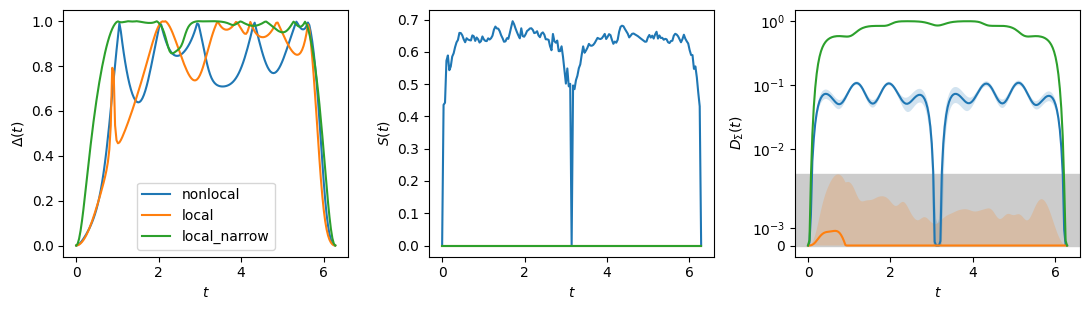

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for series in SERIES:
    axes[0].plot(QUERY_VALUES, shape_change[series], label=series)
    axes[1].plot(QUERY_VALUES, nonseparable_weight[series])
    values = prior_distance[series]
    half_width = 1.96 * prior_distance_error[series]
    axes[2].plot(QUERY_VALUES, values)
    axes[2].fill_between(
        QUERY_VALUES, np.maximum(0.0, values - half_width), values + half_width, alpha=0.2
    )
axes[2].axhspan(0.0, NOISE_CEILING, color="0.8", zorder=0)
axes[2].set_yscale("symlog", linthresh=NOISE_CEILING)
for ax, label in zip(axes, (r"$\Delta(t)$", r"$S(t)$", r"$D_\Sigma(t)$")):
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(label)
axes[0].legend()
fig.tight_layout()
plt.show()

## Summary

With the paper settings, the local generator pair keeps the query gate a product unitary at every $t$, so both absorbable series have $S \equiv 0$ exactly. Under the Haar prior $D_\Sigma(t)$ stays within the sampling null (case I), while the narrow prior moves $\Sigma_{\boldsymbol f}$ about 250 times above the noise ceiling (case II). The nonlocal pair reaches $S \approx 0.69$ and clears the null in $D_\Sigma$ (case III). Both pairs have the same joint query spectrum and use the same 13 ray modes, so none of these differences comes from additional query frequencies. The naive shape change $\Delta(t)$ approaches 1 for all three series and does not distinguish the cases.